<a href="https://colab.research.google.com/github/mukhammads-dev/computer_vision/blob/main/menu_detector_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Menu Detector!")

Menu Detector!


In [2]:
# ------------------
# Import Libraries
# ------------------
from google.colab import drive
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2

from PIL import Image, UnidentifiedImageError # python image library
from torch.utils.data import Dataset, DataLoader
import os
import numpy as np


In [3]:
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
# Define Dataset Path
DATASET_PATH = '/content/drive/MyDrive/food101_dataset'
print('Dataset_path:', DATASET_PATH)

# dataset category kop bolsa umumlashtiramiz label grouping | class consolidatation
CUSTOM_CLASS_MAPPING = {
    "hamburger": "hamburger",
    "hot_dog": "hot_dog",
    "chocolate_cake": "dessert",
    "cheesecake": "dessert",
    "pilaf": "pilaf"
}

CLASSES = ['hamburger', 'hot_dog', 'dessert', 'kebab', 'pilaf']
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)} # raqamlarni biriktirish hamburger = 0, hot_dog = 1,

NUM_CLASSES = len(CLASSES)
print(NUM_CLASSES)
print(CLASS_TO_IDX)

# Compose => bu step by step ishlarni bajarish uchun
# resize => rasmni bir hil korinishga keltirish
# tensor => raqamlarga ogiramiz
# 0.0 - 1.0 float, oldin H, W, C => C, H, W | Red, Green, Blue
# Normalize => chanellarni togirlab beradi normalize qiladi
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

Dataset_path: /content/drive/MyDrive/food101_dataset
5
{'hamburger': 0, 'hot_dog': 1, 'dessert': 2, 'kebab': 3, 'pilaf': 4}


In [5]:
# ------------------
# Custom Dataset Class
# ------------------

class FoodDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        # print('images_length', len(self.images))
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        # print('image_path', img_path)
        label = self.labels[idx]
        # print('label', label)
        try:
            image = Image.open(img_path)
            if image.mode == "P" or image.mode == "RGBA": # png | gif | RGBA
                image = image.convert("RGBA").convert("RGB")
            else:
                image = image.convert("RGB")
        except (UnidentifiedImageError, OSError):
            print(f"Skipping broken image: {img_path}")
            return self.__getitem__((idx + 1) % len(self.images))
        if self.transform:
            image = self.transform(image)
        return image, label

In [6]:
# ------------------
# Gather and Split Data
# ------------------ umumiy hamma datani split qib ajratib chiqamiz
all_images = []
for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():
    class_path = os.path.join(DATASET_PATH, original_class)
    print('class_path:', class_path)
    if not os.path.exists(class_path):
        print(f"Warning: {class_path} not found")
        continue
    for img in os.listdir(class_path):
        if img.endswith(('.jpg', '.jpeg', '.png')):
            full_path = os.path.join(class_path, img)
            all_images.append((full_path, CLASS_TO_IDX[mapped_class]))

np.random.shuffle(all_images) # dataset random
split = int(0.8 * len(all_images))
train_data = all_images[:split]  # 1000 | 800 train_data | 200 val_data
val_data = all_images[split:]

train_images, train_labels = zip(*train_data)
val_images, val_labels = zip(*val_data)

print('all_images:', all_images)

dataset = FoodDataset(train_images, train_labels)
print(len(dataset))
img, lbl = dataset[0]

class_path: /content/drive/MyDrive/food101_dataset/hamburger
class_path: /content/drive/MyDrive/food101_dataset/hot_dog
class_path: /content/drive/MyDrive/food101_dataset/chocolate_cake
class_path: /content/drive/MyDrive/food101_dataset/cheesecake
class_path: /content/drive/MyDrive/food101_dataset/pilaf
all_images: [('/content/drive/MyDrive/food101_dataset/hamburger/2988095.jpg', 0), ('/content/drive/MyDrive/food101_dataset/chocolate_cake/1668556.jpg', 2), ('/content/drive/MyDrive/food101_dataset/hamburger/1768219.jpg', 0), ('/content/drive/MyDrive/food101_dataset/chocolate_cake/2457870.jpg', 2), ('/content/drive/MyDrive/food101_dataset/chocolate_cake/2144647.jpg', 2), ('/content/drive/MyDrive/food101_dataset/cheesecake/250756.jpg', 2), ('/content/drive/MyDrive/food101_dataset/chocolate_cake/175858.jpg', 2), ('/content/drive/MyDrive/food101_dataset/hot_dog/652826.jpg', 1), ('/content/drive/MyDrive/food101_dataset/cheesecake/3288238.jpg', 2), ('/content/drive/MyDrive/food101_dataset/ham

In [7]:
train_dataset = FoodDataset(train_images, train_labels, transform=transform)
val_dataset = FoodDataset(val_images, val_labels, transform=transform)


In [8]:
# train jarayonida ketma ketlik
# batch size => birdaniga 32ta rasmni organadi
# shuffle => modeldan rasimlarni ketmaketligin yodlab olishni inkor qiladi
# num_workers => backgrounda ikita ishchi
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

In [9]:
# pretrained model | lightweight | CNN
# IMAGENET => train bolgan model 1000ta class mavjud shuncha ovqatni taniy oladi
model = mobilenet_v2(weights="IMAGENET1K_V1")

# fine-tuning => mobilent hamma feature ishlatamiz ohiriga ozimizni classni qoshamiz
# backbone => mobile net miyyasini ishlatib fine-tune qilamiz
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 97.9MB/s]


In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device', device)
model = model.to(device)

device cpu


In [11]:
criterion = nn.CrossEntropyLoss() # Loss Function => multi class slassification bu yerda model predict qilayotkanda bir biriga taqqosalb chiqadi
optimizer = optim.Adam(model.parameters(), lr=0.001) # Optimizer weight => parametrlarni update qlib beradi
torch.backends.cudnn.benchmark = True # bechmark Setting | trick bu model aynan gpu bilan ishlashda eng tez algorithmdi topib tezlashtirib

In [62]:
# Training Loop
# --------------------
NUM_EPOCHS = 10  # AI MODEL 10 martda datasetni aylanadi train
best_accuracy = 0.0  # eng zor natijani save qilish uchun

for epoch in range(NUM_EPOCHS):
    model.train()  # train mode yoqtik
    running_loss = 0.0  # yoqotishlar 70% natija bor, 30% loss korsatadi

    for images, labels in train_loader:  # forward and backward(backpropagation)
        # 1 martda train qilish jarayon forward
        # 2 martda ortga qaytish backward
        images, labels = images.to(device), labels.to(device)  # convert to gpu
        optimizer.zero_grad()  # zero the gradient katta raqamlarni nolga tushurish
        outputs = model(images)  # Forward Pass | Cnn ga image jonatadi layerla orqali tanib oladi
        # 5ta classdan kelgan outputni taminlaydi

        loss = criterion(outputs, labels)  # Calculate loss notogri va togri javobdagi tafovut
        loss.backward()  # backpropagation amalga oshadi
        optimizer.step()  # weight => har safar ozgaradi # Adam optimizer
        running_loss += loss.item()  # Track loss

    # Validation => iteration dan keyin traindi tekshiramiz
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_acc = 100 * correct / total  # Calculate Validation Accuracy
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] Loss: {running_loss/len(train_loader):.4f}, Val Accuracy: {val_acc:.2f}%")

    if val_acc > best_accuracy:
        best_accuracy = val_acc
        torch.save(model.state_dict(), '/content/menu_detector.pth')
        print("Saved new best model!")

Epoch [1/10] Loss: 0.3506, Val Accuracy: 84.49%
Saved new best model!
Epoch [2/10] Loss: 0.2904, Val Accuracy: 89.01%
Saved new best model!
Epoch [3/10] Loss: 0.1775, Val Accuracy: 89.38%
Saved new best model!
Epoch [4/10] Loss: 0.1648, Val Accuracy: 88.77%
Epoch [5/10] Loss: 0.1568, Val Accuracy: 89.38%
Epoch [6/10] Loss: 0.1520, Val Accuracy: 90.35%
Saved new best model!
Epoch [7/10] Loss: 0.1387, Val Accuracy: 88.40%
Epoch [8/10] Loss: 0.1193, Val Accuracy: 90.35%
Epoch [9/10] Loss: 0.0919, Val Accuracy: 88.52%
Epoch [10/10] Loss: 0.1021, Val Accuracy: 89.01%


# **menu_detector** model usage

device: cpu
Upload one or more images of hamburger or hot dog:


Saving seee.jpeg to seee.jpeg


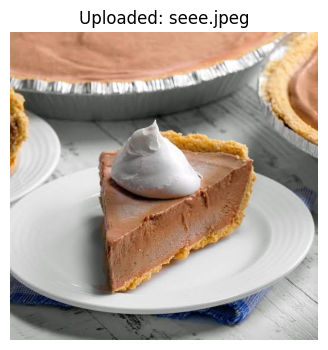

Prediction:
  dessert: 99.87%
  hot_dog: 0.11%
  hamburger: 0.01%
  pilaf: 0.00%


In [14]:
# ------------------
# Required Imports
# ------------------
import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt

# ------------------
# Define Semantic Classes
# ------------------
CLASSES = ['hamburger', 'hot_dog', 'dessert', 'kebab', 'pilaf']  # Must match training order
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}

# ------------------
# Transform for Uploaded Images (no augmentations!)
# ------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ------------------
# Load Model
# ------------------
model = mobilenet_v2(weights=None)
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.load_state_dict(torch.load('/content/menu_detector.pth', map_location='cpu'))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
model = model.to(device)
model.eval()

# ------------------
# Upload & Predict
# ------------------
print("Upload one or more images of hamburger or hot dog:")
uploaded = files.upload()

for image_name in uploaded.keys():
    image = Image.open(io.BytesIO(uploaded[image_name])).convert('RGB')

    # Display image
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Uploaded: {image_name}')
    plt.show()

    # Predict
    image_tensor = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(image_tensor)
        probs = torch.softmax(output, dim=1)[0]
        topk = torch.topk(probs, 4)

    print("Prediction:")
    for i in range(topk.indices.size(0)):
        label = CLASSES[topk.indices[i]]
        confidence = topk.values[i].item() * 100
        print(f"  {label}: {confidence:.2f}%")